In [ ]:
!pip install -q torch transformers matplotlib numpy

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from typing import Tuple
import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoConfig, AutoModelForCausalLM

import warnings
warnings.filterwarnings("ignore")
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)

print(f"Using device: {device}")

---
# 1) Advanced RoPE Scaling

RoPE is trained with a fixed context window (e.g., 2048 tokens). When the
model encounters sequences **longer** than this window at inference, the
high-frequency components of RoPE produce unseen angle values, leading to
catastrophic attention score degradation.

Three progressive solutions have been developed:

| Method | Key Idea | Used By |
|---|---|---|
| Position Interpolation (PI) | Linearly compress positions | Meta (Code Llama) |
| NTK-Aware Interpolation | Scale the **base frequency** θ | Qwen-1 |
| Dynamic NTK | Scale θ dynamically at inference | Qwen-1.5, 2 |
| YaRN | Per-dimension interpolation + temp | Qwen-2, many others |

In [3]:
def rope_standard(
    head_dim: int,
    max_len: int,
    base: float = 10000.0,
    device: str = "cpu",
) -> torch.Tensor:
    """Standard RoPE frequency computation.

    Returns:
        freqs: (max_len, head_dim // 2) — real-valued angles (m * theta_i)
    """
    # Compute base frequencies: theta_i = base^{-2i / head_dim}
    # (head_dim // 2,)
    dim_indices = torch.arange(0, head_dim, 2, device=device).float()
    theta = 1.0 / (base ** (dim_indices / head_dim))

    # Position indices
    # (max_len,)
    positions = torch.arange(max_len, device=device).float()

    # Outer product: (max_len,) × (head_dim // 2,) → (max_len, head_dim // 2)
    freqs = torch.outer(positions, theta)
    return freqs

## 1.1 Position Interpolation (PI)

The simplest context extension: linearly **compress** all positions so
that position `max_len_extended` maps to where `max_len_original` used to be.

$$m' = m \cdot \frac{L_{\text{original}}}{L_{\text{extended}}}$$

**Problem:** This uniformly scales ALL frequency dimensions, but high-frequency
components don't need scaling (they cycle quickly and stay within training
distribution). Only the low-frequency components extrapolate.

Reference: Extending Context Window of Large Language Models via
           Position Interpolation (arXiv 2306.15595)

In [4]:
def rope_position_interpolation(
    head_dim: int,
    max_len: int,
    original_max_len: int,
    base: float = 10000.0,
    device: str = "cpu",
) -> torch.Tensor:
    """Position Interpolation (PI): linearly compress positions.

    Returns:
        freqs: (max_len, head_dim // 2)
    """
    # Compute compression ratio
    scale = original_max_len / max_len

    # Same base frequencies as standard RoPE
    # (head_dim // 2,)
    dim_indices = torch.arange(0, head_dim, 2, device=device).float()
    theta = 1.0 / (base ** (dim_indices / head_dim))

    # Compressed position indices: positions are scaled down
    # (max_len,)
    positions = torch.arange(max_len, device=device).float() * scale

    # (max_len, head_dim // 2)
    freqs = torch.outer(positions, theta)
    return freqs

## 1.2 NTK-Aware Interpolation

Instead of compressing positions (which hurts high-frequency dims),
NTK-Aware scaling increases the **base frequency** $\theta_{\text{base}}$.
This spreads out the frequency spectrum non-uniformly:
- **Low-frequency** dims (which extrapolate) are interpolated more.
- **High-frequency** dims (which stay in distribution) are barely affected.

$$\theta'_{\text{base}} = \theta_{\text{base}} \cdot \alpha^{d/(d-2)}$$

where $\alpha = L_{\text{extended}} / L_{\text{original}}$ is the scaling factor.

This is the method used in **Qwen-1**.

Reference: Reddit / bloc97 "NTK-Aware Scaled RoPE" (2023)

In [5]:
def rope_ntk_aware(
    head_dim: int,
    max_len: int,
    original_max_len: int,
    base: float = 10000.0,
    device: str = "cpu",
) -> torch.Tensor:
    """NTK-Aware RoPE scaling: increase base frequency.

    The key insight from Neural Tangent Kernel theory:
    scaling the base preserves high-frequency information while
    interpolating low-frequency components.

    Returns:
        freqs: (max_len, head_dim // 2)
    """
    # Scaling factor alpha
    alpha = max_len / original_max_len

    # Rescale base frequency using NTK formula
    # Higher base → lower frequencies → longer effective wavelengths
    scaled_base = base * (alpha ** (head_dim / (head_dim - 2)))

    # Compute frequencies with rescaled base
    # (head_dim // 2,)
    dim_indices = torch.arange(0, head_dim, 2, device=device).float()
    theta = 1.0 / (scaled_base ** (dim_indices / head_dim))

    # Standard position indices (NOT compressed)
    # (max_len,)
    positions = torch.arange(max_len, device=device).float()

    # (max_len, head_dim // 2)
    freqs = torch.outer(positions, theta)
    return freqs

## 1.3 Dynamic NTK

Dynamic NTK applies NTK-Aware scaling **only when the sequence length
exceeds the training window**. When the sequence is within the original
window, standard RoPE is used. This is a simple but effective inference-time
trick used in Qwen-1.5 and Qwen-2.

```
if current_len <= original_max_len:
    use standard RoPE
else:
    alpha = current_len / original_max_len
    use NTK-Aware RoPE with alpha
```

In [6]:
def rope_dynamic_ntk(
    head_dim: int,
    current_len: int,
    original_max_len: int,
    base: float = 10000.0,
    device: str = "cpu",
) -> torch.Tensor:
    """Dynamic NTK scaling: adapt base frequency at inference time.

    If current_len <= original_max_len, returns standard RoPE.
    Otherwise, applies NTK-aware scaling with dynamic alpha.

    Returns:
        freqs: (current_len, head_dim // 2)
    """
    if current_len <= original_max_len:
        # Within training window: use standard RoPE
        return rope_standard(head_dim, current_len, base, device)
    else:
        # Beyond training window: apply NTK-aware scaling
        return rope_ntk_aware(head_dim, current_len, original_max_len, base, device)

## 1.4 YaRN — Yet another RoPE extensioN

YaRN combines the best of PI and NTK-Aware by applying
**per-dimension** interpolation ratios. Dimensions are split into
three groups based on their wavelength relative to the context window:

| Wavelength | Group | Strategy |
|---|---|---|
| λ > L × β_high | Low-freq | **Interpolate** (like PI) |
| λ < L × β_low | High-freq | **No change** (already in distribution) |
| In between | Medium-freq | **Smooth ramp** between the two |

Additionally, a **temperature scaling** factor $\sqrt{t}$ is applied to
attention logits to compensate for the distribution shift in attention
entropy caused by interpolation.

$$\theta'_i = \theta_i / \big( (1 - \gamma_i) \cdot s + \gamma_i \big)$$

where $s$ is the scale factor and $\gamma_i \in [0, 1]$ is the ramp function.

In [7]:
def rope_yarn(
    head_dim: int,
    max_len: int,
    original_max_len: int,
    base: float = 10000.0,
    beta_low: float = 1.0,
    beta_high: float = 32.0,
    device: str = "cpu",
) -> Tuple[torch.Tensor, float]:
    """YaRN: per-dimension RoPE scaling with temperature.

    Args:
        head_dim:         dimension of each attention head
        max_len:          target extended context length
        original_max_len: training context length
        base:             RoPE base frequency (default 10000)
        beta_low:         lower boundary for frequency ramp
        beta_high:        upper boundary for frequency ramp
    Returns:
        freqs:       (max_len, head_dim // 2) — angle values
        temperature: scalar — sqrt(t) for attention logit scaling
    """
    # Context extension ratio
    scale = max_len / original_max_len

    # Compute standard base frequencies
    # (head_dim // 2,)
    dim_indices = torch.arange(0, head_dim, 2, device=device).float()
    theta = 1.0 / (base ** (dim_indices / head_dim))

    # Compute wavelength for each dimension pair
    # wavelength_i = 2π / theta_i
    # (head_dim // 2,)
    wavelengths = 2 * math.pi / theta

    # Classify dimensions: compute ramp function gamma_i ∈ [0, 1]
    # Low-freq dims (long wavelength) → gamma ≈ 0 → full interpolation
    # High-freq dims (short wavelength) → gamma ≈ 1 → no change
    low_threshold = original_max_len * beta_low
    high_threshold = original_max_len * beta_high

    # Linear ramp between thresholds
    # (head_dim // 2,)
    gamma = torch.clamp(
        (wavelengths - low_threshold) / (high_threshold - low_threshold),
        0.0,
        1.0,
    )

    # Per-dimension effective scale:
    # gamma=0 → full scale (interpolation), gamma=1 → scale=1 (no change)
    # effective_scale = (1 - gamma) * scale + gamma * 1.0
    # (head_dim // 2,)
    effective_scale = (1.0 - gamma) * scale + gamma

    # Apply per-dimension scaling to frequencies
    # theta'_i = theta_i / effective_scale_i
    # Equivalently: position is compressed by effective_scale for that dim
    # (head_dim // 2,)
    theta_scaled = theta / effective_scale

    # Position indices (uncompressed)
    # (max_len,)
    positions = torch.arange(max_len, device=device).float()

    # Compute angle matrix
    # (max_len, head_dim // 2)
    freqs = torch.outer(positions, theta_scaled)

    # Temperature scaling: compensates for entropy shift in attention
    # t = 0.1 * ln(s) + 1  (empirical formula from YaRN paper)
    temperature = 0.1 * math.log(scale) + 1.0

    return freqs, temperature

YaRN temperature scaling factor: 1.1386


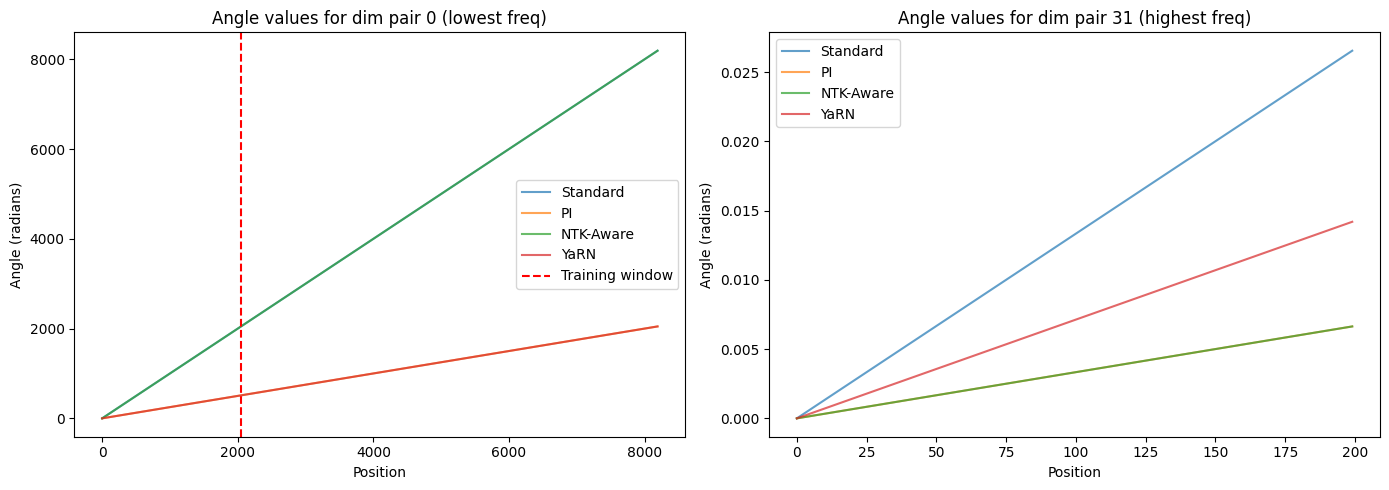

In [8]:
# ── Compare all RoPE scaling methods visually ─────────────────────
head_dim = 64
original_max_len = 2048
extended_max_len = 8192

# Compute frequencies for each method
freqs_std = rope_standard(head_dim, extended_max_len)
freqs_pi = rope_position_interpolation(head_dim, extended_max_len, original_max_len)
freqs_ntk = rope_ntk_aware(head_dim, extended_max_len, original_max_len)
freqs_yarn, yarn_temp = rope_yarn(head_dim, extended_max_len, original_max_len)

print(f"YaRN temperature scaling factor: {yarn_temp:.4f}")

# Plot the frequencies for dimension pair 0 (lowest frequency)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dim_idx = 0
positions = np.arange(extended_max_len)

ax = axes[0]
ax.set_title(f"Angle values for dim pair {dim_idx} (lowest freq)")
ax.plot(positions, freqs_std[:, dim_idx].numpy(), label="Standard", alpha=0.7)
ax.plot(positions, freqs_pi[:, dim_idx].numpy(), label="PI", alpha=0.7)
ax.plot(positions, freqs_ntk[:, dim_idx].numpy(), label="NTK-Aware", alpha=0.7)
ax.plot(positions, freqs_yarn[:, dim_idx].numpy(), label="YaRN", alpha=0.7)
ax.axvline(x=original_max_len, color="red", linestyle="--", label="Training window")
ax.set_xlabel("Position")
ax.set_ylabel("Angle (radians)")
ax.legend()

dim_idx = head_dim // 2 - 1
ax = axes[1]
ax.set_title(f"Angle values for dim pair {dim_idx} (highest freq)")
ax.plot(positions[:200], freqs_std[:200, dim_idx].numpy(), label="Standard", alpha=0.7)
ax.plot(positions[:200], freqs_pi[:200, dim_idx].numpy(), label="PI", alpha=0.7)
ax.plot(positions[:200], freqs_ntk[:200, dim_idx].numpy(), label="NTK-Aware", alpha=0.7)
ax.plot(positions[:200], freqs_yarn[:200, dim_idx].numpy(), label="YaRN", alpha=0.7)
ax.set_xlabel("Position")
ax.set_ylabel("Angle (radians)")
ax.legend()

plt.tight_layout()
plt.show()

---
# 2) Qwen2 Architecture Details

Qwen2 keeps the LLaMA-style decoder (pre-RMSNorm, SwiGLU, GQA, RoPE). What differs:

| Feature | LLaMA | Qwen2 / Qwen2.5 |
|---|---|---|
| QKV bias | No bias anywhere | **Bias on Q, K and V** projections (output projection has none) |
| Long context | Standard RoPE | Large RoPE base + **YaRN** and Dual Chunk Attention at inference |
| Sliding window | — | Supported in code for the upper layers (`max_window_layers`), but **off** (`use_sliding_window=false`) in released checkpoints |
| Vocabulary | 32K (LLaMA-2) / 128K (LLaMA-3) | **151K** byte-level BPE |

### Why QKV Bias?

A bias on Q and K adds a content-independent term to every attention logit,
$q_i^\top k_j = (W_q x_i + b_q)^\top (W_k x_j + b_k)$, which lets a head build a fixed
preference (for example towards a sink token) without spending weight capacity on it.

The cell below builds Qwen2.5-0.5B from its real config on the `meta` device (no weights
downloaded) and reads these properties directly off the modules.

In [ ]:
QWEN_NAME = "Qwen/Qwen2.5-0.5B"
qwen_config = AutoConfig.from_pretrained(QWEN_NAME)

# Instantiate on the meta device: real module structure, no weight memory
with torch.device("meta"):
    qwen = AutoModelForCausalLM.from_config(qwen_config)

attn = qwen.model.layers[0].self_attn
for name in ("q_proj", "k_proj", "v_proj", "o_proj"):
    proj = getattr(attn, name)
    print(f"{name}: {tuple(proj.weight.shape)}  bias={proj.bias is not None}")

print(f"\nnum_heads={qwen_config.num_attention_heads}, "
      f"num_kv_heads={qwen_config.num_key_value_heads}  (GQA)")
print(f"rope_theta={qwen_config.rope_parameters['rope_theta']:,.0f}")
print(f"use_sliding_window={qwen_config.use_sliding_window}, "
      f"max_window_layers={qwen_config.max_window_layers}")
print(f"vocab_size={qwen_config.vocab_size:,}")

# Summary

1. **Advanced RoPE Scaling** — a progression from Position Interpolation
   through NTK-Aware and Dynamic NTK to YaRN, each providing better
   context window extension with less performance degradation.

2. **Qwen2 Architecture** — a LLaMA-style decoder whose main structural change is
   bias on the Q/K/V projections; long context comes from the RoPE base and YaRN.